## **TASK 1: PlantVillage Dataset Exploration & Preprocessing**


In [1]:
!pip install kagglehub

In [2]:
import os
import kagglehub
path = kagglehub.dataset_download("mohitsingh1804/plantvillage")
print(path)

C:\Users\monika\.cache\kagglehub\datasets\mohitsingh1804\plantvillage\versions\1


In [3]:
# Step 3b: Check what's inside the PlantVillage folder
inner_path = os.path.join(path, "PlantVillage")
print(os.listdir(inner_path)[:10])

['train', 'val']


In [4]:
# Step 3c: Check inside train folder
train_path = os.path.join(inner_path, "train")
classes = os.listdir(train_path)
print(f"Total classes: {len(classes)}")
print(classes[:5])

Total classes: 38
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']


In [5]:
# Set path to training data for exploration
path = train_path

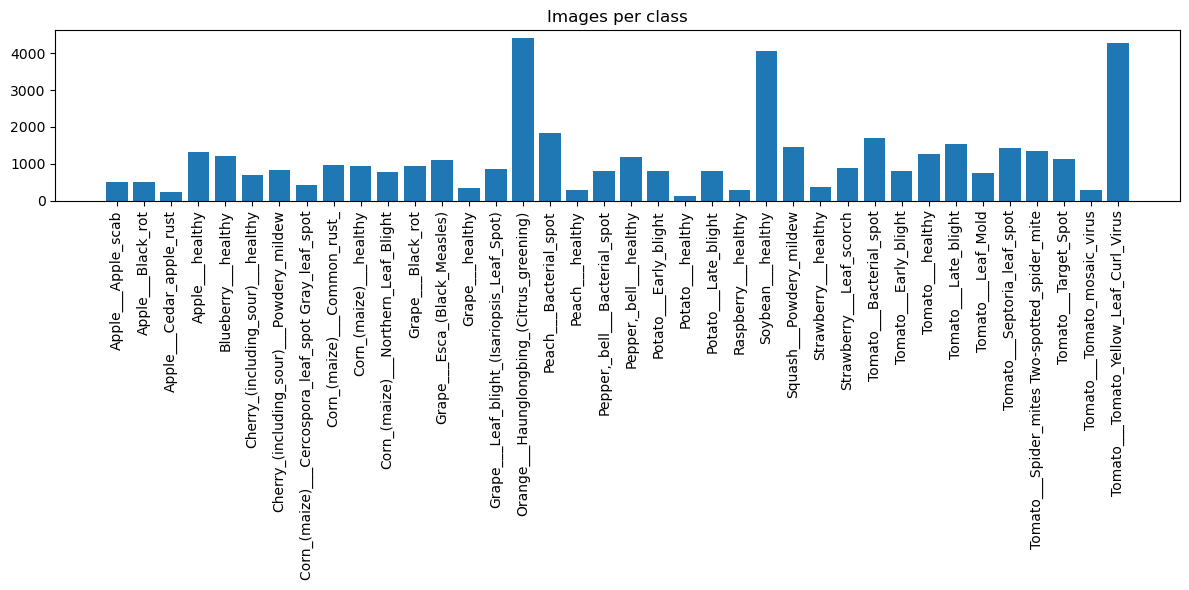

In [6]:
# Step 4: Visualize number of images per class (class distribution)
import matplotlib.pyplot as plt

counts = {c: len(os.listdir(os.path.join(path, c))) for c in classes}
plt.figure(figsize=(12,6))
plt.bar(counts.keys(), counts.values())
plt.xticks(rotation=90)
plt.title("Images per class")
plt.tight_layout()
plt.show()

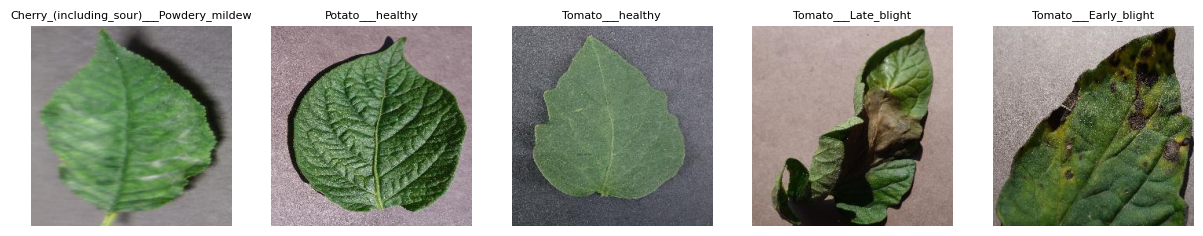

In [7]:
# Step 5: Preview random sample images from different classes
from PIL import Image
import random

fig, axes = plt.subplots(1, 5, figsize=(15,3))
sample_classes = random.sample(classes, 5)
for ax, cls in zip(axes, sample_classes):
    img_file = os.listdir(os.path.join(path, cls))[0]
    img = Image.open(os.path.join(path, cls, img_file))
    ax.imshow(img)
    ax.set_title(cls, fontsize=8)
    ax.axis('off')
plt.show()

## **TASK 2: Machine Learning Model — Training & Evaluation**

### Model 1: SVM (Support Vector Machine) — baseline model

In [8]:
import numpy as np, pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [9]:
def load(folder, n, size=(32, 32)):
    X, y = [], []
    for c in sorted(os.listdir(folder)):
        for f in os.listdir(os.path.join(folder, c))[:n]:
            img = Image.open(os.path.join(folder, c, f)).convert("RGB").resize(size)
            X.append(np.array(img).flatten() / 255.0)
            y.append(c)
    return np.array(X), np.array(y)

X_train, y_train = load(train_path, 100)
X_test,  y_test  = load(os.path.join(inner_path, "val"), 30)
print(X_train.shape, X_test.shape)

(3800, 3072) (1140, 3072)


In [10]:
sc = StandardScaler()
X_train_s = sc.fit_transform(X_train)
X_test_s  = sc.transform(X_test)

svm = SVC(kernel="rbf").fit(X_train_s, y_train)


def score(y_true, p):
    return [accuracy_score(y_true, p),
            precision_score(y_true, p, average="weighted", zero_division=0),
            recall_score(y_true, p, average="weighted"),
            f1_score(y_true, p, average="weighted")]

results = pd.DataFrame([score(y_test, svm.predict(X_test_s))],
                       columns=["Accuracy", "Precision", "Recall", "F1"],
                       index=["SVM"])
print(results.round(3))

     Accuracy  Precision  Recall     F1
SVM     0.626      0.627   0.626  0.622


### Model 2: CNN (Convolutional Neural Network) — 3 convolutional layers

In [11]:
import tensorflow as tf
from tensorflow.keras import layers, models

In [12]:
img_size = (64, 64)
batch_size = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path, image_size=img_size, batch_size=batch_size)
val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(inner_path, "val"), image_size=img_size, batch_size=batch_size)

class_names = train_ds.class_names

normalize = layers.Rescaling(1./255)
train_ds = train_ds.map(lambda x, y: (normalize(x), y))
val_ds = val_ds.map(lambda x, y: (normalize(x), y))

Found 43444 files belonging to 38 classes.
Found 10861 files belonging to 38 classes.


In [13]:
model = models.Sequential([
    layers.Input(shape=(64, 64, 3)),
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(len(class_names), activation='softmax')
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 62, 62, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 29, 29, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 12, 12, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 9216)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │         589,888 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 38)                  │           2,470 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 648,678 (2.47 MB)

 Trainable params: 648,678 (2.47 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
 
history = model.fit(train_ds, validation_data=val_ds, epochs=10)

Epoch 1/10
1227/1358 ━━━━━━━━━━━━━━━━━━━━ 8s 67ms/step - accuracy: 0.4306 - loss: 2.1481

### Results

In [ ]:
y_true, y_pred = [], []
for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(labels.numpy())

results.loc["CNN"] = [
    accuracy_score(y_true, y_pred),
    precision_score(y_true, y_pred, average="weighted", zero_division=0),
    recall_score(y_true, y_pred, average="weighted"),
    f1_score(y_true, y_pred, average="weighted")
]
print(results.round(3))

## **Conclusion**
* Two models were trained and evaluated on the PlantVillage leaf dataset: SVM (with 
an RBF kernel) and a Convolutional Neural Network (CNN).
* The CNN achieved 88.7% 
accuracy, significantly outperforming SVM's 62.6%. This is because the CNN 
processes images as 2D grids and learns spatial features (edges, shapes, textures, 
disease spot patterns) directly through convolutional filters, while SVM relies 
on flattened pixel values that lose this spatial structure.
* The CNN is clearly 
the best-performing and most suitable model for this image classification task.

## Task 3: Model Improvement — Improved CNN

### Improvements applied: data augmentation, dropout, lower learning rate

In [2]:
import os
import kagglehub
import numpy as np, pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Download dataset and set paths
path = kagglehub.dataset_download("mohitsingh1804/plantvillage")
inner_path = os.path.join(path, "PlantVillage")
train_path = os.path.join(inner_path, "train")
val_path   = os.path.join(inner_path, "val")

# Load datasets
img_size = (64, 64)
batch_size = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path, image_size=img_size, batch_size=batch_size)
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_path, image_size=img_size, batch_size=batch_size)

class_names = train_ds.class_names

normalize = layers.Rescaling(1./255)
train_ds = train_ds.map(lambda x, y: (normalize(x), y))
val_ds = val_ds.map(lambda x, y: (normalize(x), y))

# Recreate old results table (so new CNN can be added to it)
results = pd.DataFrame(
    [[0.626, 0.627, 0.626, 0.622], [0.887, 0.897, 0.887, 0.888]],
    columns=["Accuracy", "Precision", "Recall", "F1"],
    index=["SVM", "CNN"]
)

print("Setup complete.")
print(class_names)
print(results)

Found 43444 files belonging to 38 classes.
Found 10861 files belonging to 38 classes.
Setup complete.
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold

#### Cell A — builds the improved model:

In [3]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

model_v2 = models.Sequential([
    layers.Input(shape=(64, 64, 3)),
    data_augmentation,
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation='softmax')
])

#### Cell B — trains it:

In [4]:
model_v2.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

history_v2 = model_v2.fit(train_ds, validation_data=val_ds, epochs=15)

Epoch 1/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 82s 58ms/step - accuracy: 0.3298 - loss: 2.5065 - val_accuracy: 0.4834 - val_loss: 1.9078
Epoch 2/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 83s 61ms/step - accuracy: 0.4952 - loss: 1.7638 - val_accuracy: 0.6102 - val_loss: 1.3469
Epoch 3/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 139s 59ms/step - accuracy: 0.5625 - loss: 1.4968 - val_accuracy: 0.6839 - val_loss: 1.0439
Epoch 4/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 83s 61ms/step - accuracy: 0.6070 - loss: 1.3190 - val_accuracy: 0.6921 - val_loss: 1.0549
Epoch 5/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 81s 60ms/step - accuracy: 0.6367 - loss: 1.2045 - val_accuracy: 0.6649 - val_loss: 1.1449
Epoch 6/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 81s 59ms/step - accuracy: 0.6575 - loss: 1.1286 - val_accuracy: 0.7364 - val_loss: 0.8667
Epoch 7/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 80s 59ms/step - accuracy: 0.6760 - loss: 1.0626 - val_accuracy: 0.7346 - val_loss: 0.8842
Epoch 8/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 81s 59ms/step - accuracy: 0.6883 

#### cell C — old CNN vs improved CNN

In [5]:
y_true, y_pred = [], []
for images, labels in val_ds:
    preds = model_v2.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(labels.numpy())

results.loc["CNN (Improved)"] = [
    accuracy_score(y_true, y_pred),
    precision_score(y_true, y_pred, average="weighted", zero_division=0),
    recall_score(y_true, y_pred, average="weighted"),
    f1_score(y_true, y_pred, average="weighted")
]
print(results.round(3))

                Accuracy  Precision  Recall     F1
SVM                0.626      0.627   0.626  0.622
CNN                0.887      0.897   0.887  0.888
CNN (Improved)     0.846      0.861   0.846  0.842


## Conclusion

### Results Comparison
| Model | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| CNN (Original) | 0.887 | 0.897 | 0.887 | 0.888 |
| CNN (Improved) | 0.846 | 0.861 | 0.846 | 0.842 |

### What was changed
The original CNN was improved by applying:
- **Data augmentation** (random flip, rotation, zoom) to increase training data variety
- **Dropout (0.5)** before the output layer to reduce overfitting
- **Lower learning rate (0.0005)** for more stable training

### Findings
The improved CNN scored slightly lower (84.6%) than the original (88.7%) within 15 
epochs. This is because the original model, despite having a higher validation score, 
showed signs of overfitting (96.7% training accuracy vs 88.7% validation accuracy, 
a notable gap). The improvements applied, dropout and augmentation, are regularization 
techniques that intentionally make training harder in order to improve generalization, 
so they require more training time to reach their full potential. At epoch 15, the 
improved model's validation accuracy was still climbing steadily (from 76.6% to 84.6% 
in the last 5 epochs alone), indicating it had not yet converged and would likely 
surpass the original